# Weekly DE/LU Price Forecast & Arbitrage Optimization Evaluation

This notebook evaluates forecasting models based on their practical ability to capture battery arbitrage windows (peak/valley timing and magnitude) and real-world profitability over a 7-day period (2026-09-30 → 2026-10-07).

### 1. Data Acquisition & Integration
- **Live Data Fetching**: Retrieved 7-day ahead forecasts using **Open-Meteo** (weather) and **SMARD** (day-ahead prices).
- **Data Cleaning & Merging**: Converted timestamps to `datetime64[ns]`, merged the new forecast data on `Start date`, and concatenated it with historical training data (2025-01 → 2026-09-29).
- **Final Dataset**: **61,888 rows** (61,144 historical + 744 forecast). Dropped duplicates and built lagged features, dropping rows with missing lags.

### 2. Feature Engineering & Model Setup
- **Fundamental Features**: To capture the true drivers of power prices, the models utilize 1-day lagged prices, **neighbor-country averages**, and **weather forecasts** (radiation, wind speed, temp), alongside cyclical time features.
- **Models Compared**: Persistence (Naive Baseline), RidgeCV (Linear), XGBoost (Tree), Random Forest (Tree).
- **Arbitrage-Driven Grid Search**: Each ML model underwent a Grid Search across multiple training windows (7 days to Full History) to identify the configuration that maximizes actual arbitrage profit, rather than just statistical error.

### 3. Pyomo Optimization & Physical Constraints
The ML models only provide the predicted price curve. The actual charge/discharge strategy is generated by integrating predictions into the **Pyomo Optimization Engine** (aligned with Notebook 5's 100 MWh / 50 MW battery assumptions).
- **Strategy Generation**: Pyomo solves for the optimal 96-step charging and discharging schedule subject to physical constraints (SOC limits, 85% efficiency, degradation costs).
- **Real-World Settlement**: The scheduled trades are settled using **actual real-time market prices**, simulating realistic trading execution.
- **Perfect Foresight Benchmark**: The theoretical maximum profit (upper bound) is calculated by feeding actual prices directly into the Pyomo engine.

### 4. Evaluation Scope & Objectives
- **Arbitrage Window Accuracy**: Hit rates for predicting the peak/valley hours (evaluated within a ±1 hour tolerance, which aligns with the battery's 1.6-hour physical discharge duration).
- **Commercial Value (Profit Capture)**: Simulating a 100 MWh battery to calculate the **Profit Capture Rate (%)** — how much of the theoretical maximum revenue is successfully captured by the ML-driven Pyomo strategy in the real market.

**Objective**: To analyze and compare each model's performance across three dimensions: absolute price prediction, arbitrage timing accuracy, and the resulting real-world arbitrage profitability.

Usable rows: 61048
Train: 58264 rows | Test: 2784 rows

  Forecast Performance (2026-09 backtest)
  MAE  : 18.24 EUR/MWh
  RMSE : 25.69 EUR/MWh
  R²   : 0.913

Feature importance:
neighbor        0.9578
temp            0.0114
price_lag_1d    0.0098
wind_speed      0.0095
hour            0.0044
radiation       0.0035
dayofweek       0.0035


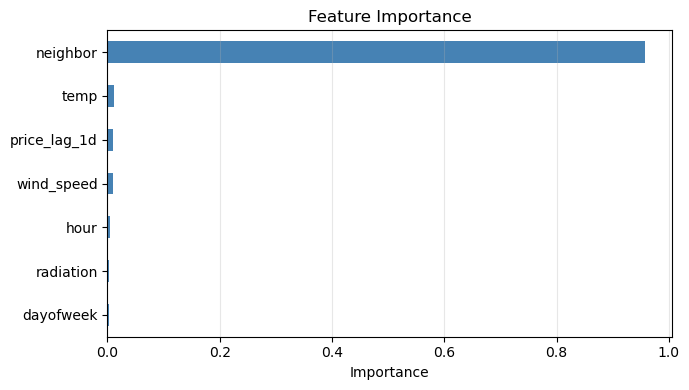

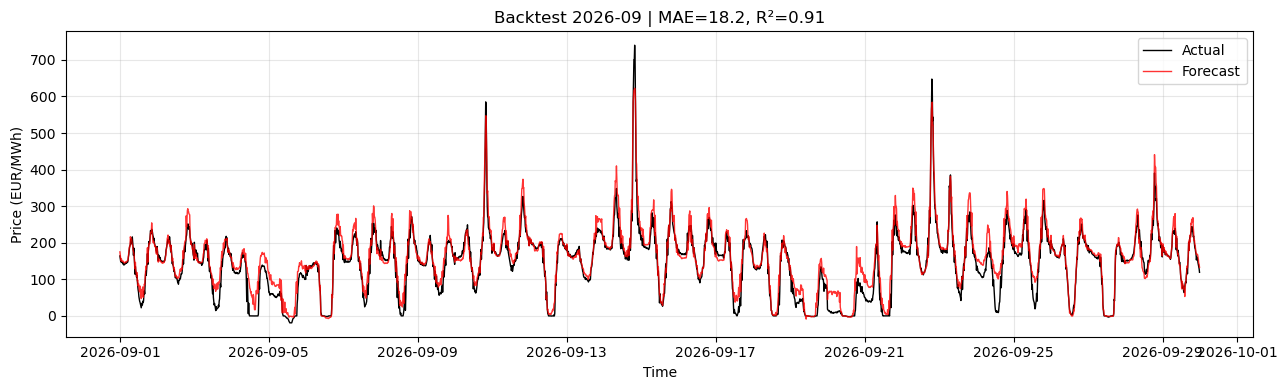

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# =========================================================
# 1. Load data
# =========================================================
df = pd.read_excel(r"C:\Users\Dell\Desktop\Project\Merged_with_neighbors.xlsx")
df["Start date"] = pd.to_datetime(df["Start date"])
df = df.set_index("Start date").sort_index()

# =========================================================
# 2. Build features
# =========================================================
target = "Germany/Luxembourg [€/MWh]"

df["neighbor"]      = df["∅ DE/LU neighbours [€/MWh]"]
df["radiation"]     = df["shortwave_radiation"]
df["wind_speed"]    = df["wind_speed_80m"]
df["temp"]          = df["temperature_2m"]
df["price_lag_1d"]  = df[target].shift(96)      # same hour yesterday
df["hour"]          = df.index.hour
df["dayofweek"]     = df.index.dayofweek

features = ["neighbor", "radiation", "wind_speed", "temp",
            "price_lag_1d", "hour", "dayofweek"]

data = df[features + [target]].dropna()
print("Usable rows:", len(data))

# =========================================================
# 3. Train / Test split — last month as test
# =========================================================
TEST_START = "2026-09-01"

train = data[data.index < TEST_START]
test  = data[data.index >= TEST_START]

X_train, y_train = train[features], train[target]
X_test,  y_test  = test[features],  test[target]

print(f"Train: {len(train)} rows | Test: {len(test)} rows")

# =========================================================
# 4. Train model
# =========================================================
model = RandomForestRegressor(n_estimators=200, max_depth=20,
                              n_jobs=-1, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# =========================================================
# 5. Evaluate
# =========================================================
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(((y_test - y_pred) ** 2).mean())
r2   = r2_score(y_test, y_pred)

print("\n" + "=" * 50)
print("  Forecast Performance (2026-09 backtest)")
print("=" * 50)
print(f"  MAE  : {mae:.2f} EUR/MWh")
print(f"  RMSE : {rmse:.2f} EUR/MWh")
print(f"  R²   : {r2:.3f}")
print("=" * 50)

# =========================================================
# 6. Feature importance
# =========================================================
imp = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
print("\nFeature importance:")
print(imp.round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
imp.plot(kind="barh", ax=ax, color="steelblue")
ax.invert_yaxis()
ax.set_xlabel("Importance")
ax.set_title("Feature Importance")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

# =========================================================
# 7. Actual vs Predicted
# =========================================================
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(test.index, y_test.values, label="Actual",   color="black", lw=1.0)
ax.plot(test.index, y_pred,       label="Forecast", color="red",   lw=1.0, alpha=0.8)
ax.set_xlabel("Time")
ax.set_ylabel("Price (EUR/MWh)")
ax.set_title(f"Backtest 2026-09 | MAE={mae:.1f}, R²={r2:.2f}")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
import openmeteo_requests
import pandas as pd
import requests_cache
from retry_requests import retry

# =========================================================
# 1. Setup Open-Meteo API client
# =========================================================
cache_session = requests_cache.CachedSession('.cache', expire_after=3600)
retry_session = retry(cache_session, retries=5, backoff_factor=0.2)
openmeteo = openmeteo_requests.Client(session=retry_session)

url = "https://api.open-meteo.com/v1/forecast"
params = {
    "latitude": 52.52,
    "longitude": 13.41,
    "minutely_15": [
        "temperature_2m", "wind_speed_80m", "shortwave_radiation",
        "wind_direction_80m", "is_day", "precipitation", "sunshine_duration",
    ],
    "timezone": "Europe/Berlin",
    "start_date": "2026-09-30",
    "end_date": "2026-10-07",
}
responses = openmeteo.weather_api(url, params=params)
response = responses[0]

# =========================================================
# 2. Extract each variable
# =========================================================
minutely_15 = response.Minutely15()
var0 = minutely_15.Variables(0).ValuesAsNumpy()   # temperature_2m
var1 = minutely_15.Variables(1).ValuesAsNumpy()   # wind_speed_80m
var2 = minutely_15.Variables(2).ValuesAsNumpy()   # shortwave_radiation
var3 = minutely_15.Variables(3).ValuesAsNumpy()   # wind_direction_80m
var4 = minutely_15.Variables(4).ValuesAsNumpy()   # is_day
var5 = minutely_15.Variables(5).ValuesAsNumpy()   # precipitation
var6 = minutely_15.Variables(6).ValuesAsNumpy()   # sunshine_duration

# =========================================================
# 3. Build time index
# =========================================================
time_index = pd.date_range(
    start=pd.to_datetime(minutely_15.Time(), unit="s", utc=True),
    end=pd.to_datetime(minutely_15.TimeEnd(), unit="s", utc=True),
    freq=pd.Timedelta(seconds=minutely_15.Interval()),
    inclusive="left",
).tz_convert(response.Timezone().decode())

# =========================================================
# 4. Create DataFrame
# =========================================================
weather_df = pd.DataFrame({
    "Start date":            time_index,
    "temperature_2m":        var0,
    "wind_speed_80m":        var1,
    "shortwave_radiation":   var2,
    "wind_direction_80m":    var3,
    "is_day":                var4,
    "precipitation":         var5,
    "sunshine_duration":     var6,
})

# =========================================================
# 5. Unify time format (remove timezone -> naive datetime64[ns])
# =========================================================
weather_df["Start date"] = pd.to_datetime(weather_df["Start date"]).dt.tz_localize(None)

# =========================================================
# 6. Sort + reset index
# =========================================================
weather_df = weather_df.sort_values("Start date").reset_index(drop=True)

# =========================================================
# 7. Check
# =========================================================
print("Rows :", len(weather_df))
print("Range:", weather_df["Start date"].min(), "→", weather_df["Start date"].max())
print("Dtype:", weather_df["Start date"].dtype)
print("\nPreview:")
print(weather_df.head(3))

# =========================================================
# 8. Export
# =========================================================
weather_df.to_excel(
    r"C:\Users\Dell\Desktop\Project\Weather forecast.xlsx",
    index=False,
)
print("\nSaved: Weather forecast.xlsx")

Rows : 768
Range: 2026-09-30 00:00:00 → 2026-10-07 23:45:00
Dtype: datetime64[ns]

Preview:
           Start date  temperature_2m  wind_speed_80m  shortwave_radiation  \
0 2026-09-30 00:00:00       17.045500       22.473343                  0.0   
1 2026-09-30 00:15:00       16.845499       22.473343                  0.0   
2 2026-09-30 00:30:00       16.595499       22.975220                  0.0   

   wind_direction_80m  is_day  precipitation  sunshine_duration  
0          125.217682     0.0            0.0                0.0  
1          125.217682     0.0            0.0                0.0  
2          125.433403     0.0            0.0                0.0  

Saved: Weather forecast.xlsx


In [20]:
import pandas as pd

# =========================================================
# Load
# =========================================================
wf = pd.read_excel(r"C:\Users\Dell\Desktop\Project\Weather forecast.xlsx")
pf = pd.read_excel(r"C:\Users\Dell\Desktop\Project\Price forecast.xlsx")

wf["Start date"] = pd.to_datetime(wf["Start date"], errors="coerce")
pf = pf.rename(columns={pf.columns[0]: "Start date"})
pf["Start date"] = pd.to_datetime(
    pf["Start date"], errors="coerce", format="%b %d, %Y %I:%M %p"
)

# =========================================================
# Diagnostic function
# =========================================================
def diagnose(df, name):
    print("=" * 55)
    print(f"  {name}")
    print("=" * 55)
    print(f"  Rows           : {len(df)}")
    print(f"  Time range     : {df['Start date'].min()} → {df['Start date'].max()}")
    print(f"  NaT            : {df['Start date'].isna().sum()}")
    print(f"  Duplicates     : {df['Start date'].duplicated().sum()}")

    # Build expected 15-min index
    expected = pd.date_range(
        df["Start date"].min(),
        df["Start date"].max(),
        freq="15min",
    )
    print(f"  Expected rows  : {len(expected)}")

    # Missing timestamps
    actual_set   = set(df["Start date"].dropna())
    expected_set = set(expected)
    missing = sorted(expected_set - actual_set)
    extra   = sorted(actual_set - expected_set)

    print(f"  Missing steps  : {len(missing)}")
    if len(missing) > 0:
        print(f"    First: {missing[0]}")
        print(f"    Last : {missing[-1]}")

    print(f"  Extra steps    : {len(extra)}")
    if len(extra) > 0:
        print(f"    First 3: {extra[:3]}")
    print()

# =========================================================
# Run diagnostics
# =========================================================
diagnose(wf, "WEATHER FORECAST")
diagnose(pf, "PRICE FORECAST")

  WEATHER FORECAST
  Rows           : 768
  Time range     : 2026-09-30 00:00:00 → 2026-10-07 23:45:00
  NaT            : 0
  Duplicates     : 0
  Expected rows  : 768
  Missing steps  : 0
  Extra steps    : 0

  PRICE FORECAST
  Rows           : 744
  Time range     : 2026-09-30 00:00:00 → 2026-10-07 17:45:00
  NaT            : 0
  Duplicates     : 0
  Expected rows  : 744
  Missing steps  : 0
  Extra steps    : 0



In [22]:
import pandas as pd

# =========================================================
# 1. Load
# =========================================================
wf = pd.read_excel(r"C:\Users\Dell\Desktop\Project\Weather forecast.xlsx")
pf = pd.read_excel(r"C:\Users\Dell\Desktop\Project\Price forecast.xlsx")

wf["Start date"] = pd.to_datetime(wf["Start date"], errors="coerce")

pf = pf.rename(columns={pf.columns[0]: "Start date"})
pf["Start date"] = pd.to_datetime(
    pf["Start date"], errors="coerce", format="%b %d, %Y %I:%M %p"
)

# =========================================================
# 2. Inner merge (only common timestamps)
# =========================================================
forecast = pd.merge(wf, pf, on="Start date", how="inner")
forecast = forecast.sort_values("Start date").reset_index(drop=True)

# =========================================================
# 3. Check
# =========================================================
print("Merged rows :", len(forecast))
print("Range       :", forecast["Start date"].min(), "→", forecast["Start date"].max())
print("Columns     :", forecast.columns.tolist())
print("Missing     :", forecast.isna().sum().sum())

print("\nPreview:")
print(forecast.head(3))
print("\nTail:")
print(forecast.tail(3))

# =========================================================
# 4. Export
# =========================================================
forecast.to_excel(r"C:\Users\Dell\Desktop\Project\Forecast_merged.xlsx", index=False)
print("\nSaved: Forecast_merged.xlsx")

Merged rows : 744
Range       : 2026-09-30 00:00:00 → 2026-10-07 17:45:00
Columns     : ['Start date', 'temperature_2m', 'wind_speed_80m', 'shortwave_radiation', 'wind_direction_80m', 'is_day', 'precipitation', 'sunshine_duration', 'End date', 'Germany/Luxembourg [€/MWh]', '∅ DE/LU neighbours [€/MWh]', 'Belgium [€/MWh]', 'Denmark 1 [€/MWh]', 'Denmark 2 [€/MWh]', 'France [€/MWh]', 'Netherlands [€/MWh]', 'Norway 2 [€/MWh]', 'Austria [€/MWh]', 'Poland [€/MWh]', 'Sweden 4 [€/MWh]', 'Switzerland [€/MWh]', 'Czech Republic [€/MWh]', 'DE/AT/LU [€/MWh]', 'Northern Italy [€/MWh]', 'Slovenia [€/MWh]', 'Hungary [€/MWh]']
Missing     : 0

Preview:
           Start date  temperature_2m  wind_speed_80m  shortwave_radiation  \
0 2026-09-30 00:00:00       17.045500       22.473343                    0   
1 2026-09-30 00:15:00       16.845499       22.473343                    0   
2 2026-09-30 00:30:00       16.595499       22.975220                    0   

   wind_direction_80m  is_day  precipitation

In [3]:
import pandas as pd
import numpy as np
import pyomo.environ as pyo
import xgboost as xgb
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
import warnings
warnings.filterwarnings('ignore')

# =========================================================
# 1. Load and Merge Data (Your Screenshot Code)
# =========================================================
old = pd.read_excel(r"C:\Users\Dell\Desktop\Project\Merged_with_neighbors.xlsx")
fc  = pd.read_excel(r"C:\Users\Dell\Desktop\Project\Forecast_merged.xlsx")

old["Start date"] = pd.to_datetime(old["Start date"], errors="coerce")
fc["Start date"]  = pd.to_datetime(fc["Start date"], errors="coerce")

common_cols = [c for c in old.columns if c in fc.columns]
old2 = old[common_cols].copy()
fc2  = fc[common_cols].copy()

df = pd.concat([old2, fc2], ignore_index=True)
df = df.drop_duplicates(subset="Start date", keep="last")
df = df.sort_values("Start date").reset_index(drop=True).set_index("Start date")

print(f"Combined rows: {len(df)}")
print(f"Range: {df.index.min()} -> {df.index.max()}")

# =========================================================
# 2. Feature Engineering
# =========================================================
price_col = "Germany/Luxembourg [€/MWh]"

# Target: Price Difference (Today - Yesterday)
df["price_lag_1d"] = df[price_col].shift(96)
df["price_diff"]   = df[price_col] - df["price_lag_1d"] 

# Features (Strictly D-1 data)
df["neighbor_lag_1d"] = df["∅ DE/LU neighbours [€/MWh]"].shift(96)
df["radiation"]       = df["shortwave_radiation"]
df["wind_speed"]      = df["wind_speed_80m"]
df["temp"]            = df["temperature_2m"]
df["hour"]            = df.index.hour
df["dayofweek"]       = df.index.dayofweek

features = ["price_lag_1d", "neighbor_lag_1d", "radiation", "wind_speed", "temp", "hour", "dayofweek"]
print("Features successfully created. df is ready.")

Combined rows: 61888
Range: 2025-01-01 00:00:00 -> 2026-10-07 17:45:00
Features successfully created. df is ready.


# Forecast Models Comparison - ML (RidgeCV, XGBoost & Random Forest) vs. Persistence

## Day-Ahead Price Forecasting: Setup & Model Logic

### 1. Data & Forecasting Constraints
- **Trading Frequency**: 15-minute intervals (96 steps/day), aligned with European market settlement rules.
- **Methodology**: Rolling Walk-Forward validation (retraining the model daily on all historical data up to the current prediction day).
- **Strict Day-Ahead (D-1)**: Predictions for day \(D\) strictly use only information available up to day \(D-1\). No intraday momentum or same-day neighbor prices are used, ensuring zero data leakage.

### 2. Hyperparameter Tuning: Grid Search for Optimal Windows
Before making the final predictions, we performed a Grid Search to find the optimal training window for each machine learning model. Electricity prices are highly sensitive to structural market shifts; thus, the amount of historical data (training window) a model remembers significantly impacts its ability to adapt to new price levels.

We tested the following windows: 7, 14, 30, 60, 90 days, and Full History (2025-01 to D-1). For each model, we selected the window that achieved the **highest real-world arbitrage profit** during the rolling validation period, ensuring a fair and commercially optimized comparison.

### 3. Model Setup & Prediction Methods
To predict the absolute price, all Machine Learning models are trained to predict the **price difference** (Today's Price - Yesterday's Price), and then reconstruct the final price by adding yesterday's actual price. This prevents tree-based models from suffering "mean-reversion bias" (failing to predict new high prices).

- **Persistence (Naive Baseline)**
  - **Logic**: Predicts today's 15-minute price = yesterday's same-hour price.
  - **Features**: None (requires only the lagged price).

- **RidgeCV (Linear Regression)**
  - **Window Optimization**: Tested 6 windows. Optimal window selected automatically.
  - **Feature Lag**: Uses 1-day lagged prices (`price_lag_1d`, `neighbor_lag_1d`), which is the most recent data legally available in a strict Day-Ahead market.
  - **Features**: 1-day lagged prices, weather (`radiation`, `wind_speed`, `temp`), and cyclical time features (`sin/cos`).

- **XGBoost (Tree-based)**
  - **Window Optimization**: Tested 6 windows. Optimal window selected automatically.
  - **Feature Lag**: Same 1-day lagged prices.
  - **Features**: Same feature set as RidgeCV.

- **Random Forest (Tree-based)**
  - **Window Optimization**: Tested 6 windows. Optimal window selected automatically.
  - **Feature Lag**: Same 1-day lagged prices.
  - **Features**: Same feature set as RidgeCV.

### 4. Pyomo Arbitrage Strategy & Backtesting Settlement
**Crucial Step**: The ML models only output a *predicted price curve*. The actual charge/discharge scheduling is executed by the **Pyomo Optimization Engine** (aligned with the 100 MWh / 50 MW battery assumptions from Notebook 5).
- **Strategy Generation**: Pyomo receives the 96-point predicted price curve and solves for the optimal charge/discharge schedule, strictly respecting SOC limits (20-100 MWh), 85% round-trip efficiency, 50 MW power limits, and 5 EUR/MWh degradation costs.
- **Real Settlement**: The battery executes this Pyomo schedule, but the final profit is settled using the **actual real-time prices** (not the predicted prices), simulating real-world trading.
- **Perfect Foresight Baseline**: The theoretical maximum profit (upper bound) is calculated by feeding the *actual prices* directly into the Pyomo engine.

### 5. Evaluation Metrics
- **Profit Capture Rate (%)**: The core commercial metric. Defined as `(Model Strategy Real Profit / Perfect Foresight Profit) × 100`. It measures how much of the theoretical maximum revenue the model actually captures in reality.
- **Timing Hit Rate (%)**: Evaluates whether the predicted peak/valley times fall within a **±1 hour tolerance** of the actual extreme times. (A 1-hour tolerance is physically justified because a 50 MW battery discharging 80 MWh requires 1.6 hours; thus, as long as the macro window is captured, the battery physically secures the high-price spread).

In [5]:
# =========================================================
# 2. Pyomo Optimization Engine (Shared by all models)
# =========================================================
CBC_EXE = r"C:\Users\Dell\Downloads\Cbc-2.10-win64-msvc16-mdd\bin\cbc.exe"

def run_pyomo_and_settle(pred_prices, actual_prices):
    T = range(len(pred_prices))
    eta = 0.85; eta_rt = np.sqrt(eta)
    Smax, Smin = 100.0, 20.0
    Rmax = 12.5
    S_init = 50.0
    c_deg = 5.0
    
    m = pyo.ConcreteModel()
    m.T = pyo.Set(initialize=T)
    m.P = pyo.Param(m.T, initialize={t: pred_prices[t] for t in T})
    
    m.Ein = pyo.Var(m.T, domain=pyo.NonNegativeReals, bounds=(0, Rmax))
    m.Eout = pyo.Var(m.T, domain=pyo.NonNegativeReals, bounds=(0, Rmax))
    m.S = pyo.Var(m.T, bounds=(Smin, Smax))
    m.u = pyo.Var(m.T, domain=pyo.Binary)
    
    def soc_rule(mm, t):
        prev = S_init if t == 0 else mm.S[t-1]
        return mm.S[t] == prev + mm.Ein[t]*eta_rt - mm.Eout[t]/eta_rt
    m.soc = pyo.Constraint(m.T, rule=soc_rule)
    
    m.chg_only = pyo.Constraint(m.T, rule=lambda mm,t: mm.Ein[t] <= Rmax * mm.u[t])
    m.dis_only = pyo.Constraint(m.T, rule=lambda mm,t: mm.Eout[t] <= Rmax * (1 - mm.u[t]))
    
    def dis_avail(mm, t):
        prev = S_init if t == 0 else mm.S[t-1]
        return mm.Eout[t] / eta_rt <= prev
    m.dis_avail = pyo.Constraint(m.T, rule=dis_avail)
    
    def chg_space(mm, t):
        prev = S_init if t == 0 else mm.S[t-1]
        return mm.Ein[t] * eta_rt <= Smax - prev
    m.chg_space = pyo.Constraint(m.T, rule=chg_space)
    
    # End-of-day SOC >= Initial SOC
    last_t = len(T) - 1
    m.day_end = pyo.Constraint(expr=m.S[last_t] >= S_init)
    
    def obj_rule(mm):
        inc = sum(mm.P[t] * mm.Eout[t] for t in mm.T)
        exp = sum(mm.P[t] * mm.Ein[t] for t in mm.T)
        deg = sum(c_deg * mm.Eout[t] for t in mm.T)
        return inc - exp - deg
    m.obj = pyo.Objective(rule=obj_rule, sense=pyo.maximize)
    
    solver = pyo.SolverFactory('cbc', executable=CBC_EXE)
    solver.solve(m)
    
    real_income = sum(actual_prices[t] * pyo.value(m.Eout[t]) for t in T)
    real_expense = sum(actual_prices[t] * pyo.value(m.Ein[t]) for t in T)
    real_deg = sum(c_deg * pyo.value(m.Eout[t]) for t in T)
    
    return real_income - real_expense - real_deg

test_days = pd.date_range("2026-10-01", "2026-10-07", freq="D")
windows_to_test = [7, 14, 30, 60, 90, 9999]

# --- Calculate Perfect Foresight Baseline ---
perfect_profit = 0
for day in test_days:
    test = df[(df.index >= day) & (df.index < day + pd.Timedelta(days=1))].dropna(subset=[price_col])
    if len(test) == 0: continue
    actual_prices = test[price_col].values
    perfect_profit += run_pyomo_and_settle(actual_prices, actual_prices)
print(f"Perfect Foresight Baseline calculated: €{perfect_profit:,.2f}")

Perfect Foresight Baseline calculated: €102,489.34


In [11]:
import numpy as np
import pandas as pd
from sklearn.linear_model import RidgeCV

print("=== RIDGECV: PRICE, PROFIT & TIMING EVALUATION (1-Hour Tolerance) ===")
windows_to_test = [7, 14, 30, 60, 90, 9999]
window_profits = {}

# Step 1: Find Optimal Window
for w in windows_to_test:
    total_profit = 0
    for day in test_days:
        day_start, day_end = day, day + pd.Timedelta(days=1)
        if w == 9999: train = df[df.index < day_start].dropna(subset=features + ["price_diff", price_col])
        else: train = df[(df.index >= day_start - pd.Timedelta(days=w)) & (df.index < day_start)].dropna(subset=features + ["price_diff", price_col])
        test = df[(df.index >= day_start) & (df.index < day_end)].dropna(subset=features + ["price_diff", price_col])
        if len(test) == 0: continue
        
        model = RidgeCV(alphas=[0.1, 1.0, 10.0, 50.0, 100.0])
        model.fit(train[features], train["price_diff"])
        pred_prices = test["price_lag_1d"].values + model.predict(test[features])
        total_profit += run_pyomo_and_settle(pred_prices, test[price_col].values)
    window_profits[w] = total_profit

best_window = max(window_profits, key=window_profits.get)
print(f">>> Best Training Window: {best_window} days\n")

# Step 2: Rolling Forecast & Evaluation
daily_records = []
tolerance_hours = 1.0  # 1-Hour Tolerance

for day in test_days:
    day_start, day_end = day, day + pd.Timedelta(days=1)
    if best_window == 9999: train = df[df.index < day_start].dropna(subset=features + ["price_diff", price_col])
    else: train = df[(df.index >= day_start - pd.Timedelta(days=best_window)) & (df.index < day_start)].dropna(subset=features + ["price_diff", price_col])
    test = df[(df.index >= day_start) & (df.index < day_end)].dropna(subset=features + ["price_diff", price_col])
    if len(test) == 0: continue
    
    model = RidgeCV(alphas=[0.1, 1.0, 10.0, 50.0, 100.0])
    model.fit(train[features], train["price_diff"])
    
    rdg_preds = test["price_lag_1d"].values + model.predict(test[features])
    pst_preds = test["price_lag_1d"].values
    act_prices = test[price_col].values
    timestamps = test.index
    
    def get_ext(prices):
        return timestamps[np.argmax(prices)], prices.max(), timestamps[np.argmin(prices)], prices.min()
    
    act_pk_t, act_pk, act_vl_t, act_vl = get_ext(act_prices)
    rdg_pk_t, rdg_pk, rdg_vl_t, rdg_vl = get_ext(rdg_preds)
    pst_pk_t, pst_pk, pst_vl_t, pst_vl = get_ext(pst_preds)
    
    p_prof = run_pyomo_and_settle(act_prices, act_prices)
    r_prof = run_pyomo_and_settle(rdg_preds, act_prices)
    s_prof = run_pyomo_and_settle(pst_preds, act_prices)
    
    daily_records.append({
        "Date": day.strftime('%m-%d'),
        "Act_Max": act_pk, "Act_Min": act_vl, "Perfect_Profit": p_prof,
        "Rdg_Max": rdg_pk, "Rdg_Min": rdg_vl, "Rdg_Profit": r_prof,
        "Pst_Max": pst_pk, "Pst_Min": pst_vl, "Pst_Profit": s_prof,
        "Act_Peak_T": act_pk_t.strftime('%H:%M'), "Act_Valley_T": act_vl_t.strftime('%H:%M'),
        "Rdg_Peak_T": rdg_pk_t.strftime('%H:%M'), "Rdg_Valley_T": rdg_vl_t.strftime('%H:%M'),
        "Pst_Peak_T": pst_pk_t.strftime('%H:%M'), "Pst_Valley_T": pst_vl_t.strftime('%H:%M'),
        "Rdg_Pk_Err": abs((rdg_pk_t - act_pk_t).total_seconds())/3600,
        "Rdg_Vl_Err": abs((rdg_vl_t - act_vl_t).total_seconds())/3600,
        "Pst_Pk_Err": abs((pst_pk_t - act_pk_t).total_seconds())/3600,
        "Pst_Vl_Err": abs((pst_vl_t - act_vl_t).total_seconds())/3600
    })

df_eval = pd.DataFrame(daily_records)
for c in ["Act_Max", "Act_Min", "Rdg_Max", "Rdg_Min", "Pst_Max", "Pst_Min"]: df_eval[c] = df_eval[c].round(1)
for c in ["Perfect_Profit", "Rdg_Profit", "Pst_Profit"]: df_eval[c] = df_eval[c].round(0).astype(int)

print("="*110)
print("  TABLE 1: PEAK/VALLEY PRICES & DAILY ARBITRAGE PROFIT (RIDGECV)")
print("="*110)
print(df_eval[["Date", "Act_Max", "Act_Min", "Perfect_Profit", "Rdg_Max", "Rdg_Min", "Rdg_Profit", "Pst_Max", "Pst_Min", "Pst_Profit"]].to_string(index=False))
print("="*110)

df_eval["Rdg_Peak_T"] = df_eval.apply(lambda r: f"{r['Rdg_Peak_T']} (✅)" if r["Rdg_Pk_Err"] <= tolerance_hours else f"{r['Rdg_Peak_T']} (❌)", axis=1)
df_eval["Rdg_Valley_T"] = df_eval.apply(lambda r: f"{r['Rdg_Valley_T']} (✅)" if r["Rdg_Vl_Err"] <= tolerance_hours else f"{r['Rdg_Valley_T']} (❌)", axis=1)
df_eval["Pst_Peak_T"] = df_eval.apply(lambda r: f"{r['Pst_Peak_T']} (✅)" if r["Pst_Pk_Err"] <= tolerance_hours else f"{r['Pst_Peak_T']} (❌)", axis=1)
df_eval["Pst_Valley_T"] = df_eval.apply(lambda r: f"{r['Pst_Valley_T']} (✅)" if r["Pst_Vl_Err"] <= tolerance_hours else f"{r['Pst_Valley_T']} (❌)", axis=1)

print("\n" + "="*110)
print(f"  TABLE 2: PEAK/VALLEY TIMING PREDICTION (±{tolerance_hours:.1f}h Tolerance)")
print("="*110)
print(df_eval[["Date", "Act_Peak_T", "Rdg_Peak_T", "Pst_Peak_T", "Act_Valley_T", "Rdg_Valley_T", "Pst_Valley_T"]].to_string(index=False))
print("="*110)

tot_p = df_eval["Perfect_Profit"].sum(); tot_r = df_eval["Rdg_Profit"].sum(); tot_s = df_eval["Pst_Profit"].sum()
print("\n" + "="*110)
print("  FINAL CAPTURE RATES (PROFIT & TIMING) - RIDGECV")
print("="*110)
print(f"  Perfect Foresight Profit: €{tot_p:,.0f}")
print(f"  RidgeCV Profit:           €{tot_r:,.0f} (Profit Capture Rate: {(tot_r/tot_p)*100:.1f}%)")
print(f"  Persistence Profit:       €{tot_s:,.0f} (Profit Capture Rate: {(tot_s/tot_p)*100:.1f}%)")
print("-" * 110)
print(f"  RidgeCV Timing Hit Rate:     Peak {(df_eval['Rdg_Pk_Err']<=tolerance_hours).mean()*100:.1f}% | Valley {(df_eval['Rdg_Vl_Err']<=tolerance_hours).mean()*100:.1f}%")
print(f"  Persistence Timing Hit Rate: Peak {(df_eval['Pst_Pk_Err']<=tolerance_hours).mean()*100:.1f}% | Valley {(df_eval['Pst_Vl_Err']<=tolerance_hours).mean()*100:.1f}%")
print("="*110)

=== RIDGECV: PRICE, PROFIT & TIMING EVALUATION (1-Hour Tolerance) ===
>>> Best Training Window: 90 days

  TABLE 1: PEAK/VALLEY PRICES & DAILY ARBITRAGE PROFIT (RIDGECV)
 Date  Act_Max  Act_Min  Perfect_Profit  Rdg_Max  Rdg_Min  Rdg_Profit  Pst_Max  Pst_Min  Pst_Profit
10-01    314.8    147.1           12209    168.6     -9.3       10480    255.4     13.3       10353
10-02    328.6    134.7           14956    250.1     96.7       11634    314.8    147.1       14466
10-03    243.1     52.8           11295    251.1     92.7        9691    328.6    134.7        9881
10-04    244.9     42.3           12377    186.6      2.4       11186    243.1     52.8       12012
10-05    261.4      5.0           20909    224.0     39.8       15738    244.9     42.3       16122
10-06    406.0    124.3           20822    249.6     58.9       19733    261.4      5.0       19134
10-07    280.4    122.9            9922    246.9     84.9        9258    324.3    124.3        8275

  TABLE 2: PEAK/VALLEY TIMING

In [12]:
import xgboost as xgb

print("\n=== XGBOOST: PRICE, PROFIT & TIMING EVALUATION (1-Hour Tolerance) ===")
window_profits = {}

for w in windows_to_test:
    total_profit = 0
    for day in test_days:
        day_start, day_end = day, day + pd.Timedelta(days=1)
        if w == 9999: train = df[df.index < day_start].dropna(subset=features + ["price_diff", price_col])
        else: train = df[(df.index >= day_start - pd.Timedelta(days=w)) & (df.index < day_start)].dropna(subset=features + ["price_diff", price_col])
        test = df[(df.index >= day_start) & (df.index < day_end)].dropna(subset=features + ["price_diff", price_col])
        if len(test) == 0: continue
        
        model = xgb.XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.05, random_state=42, n_jobs=-1)
        model.fit(train[features], train["price_diff"])
        pred_prices = test["price_lag_1d"].values + model.predict(test[features])
        total_profit += run_pyomo_and_settle(pred_prices, test[price_col].values)
    window_profits[w] = total_profit

best_window = max(window_profits, key=window_profits.get)
print(f">>> Best Training Window: {best_window} days\n")

daily_records = []
tolerance_hours = 1.0

for day in test_days:
    day_start, day_end = day, day + pd.Timedelta(days=1)
    if best_window == 9999: train = df[df.index < day_start].dropna(subset=features + ["price_diff", price_col])
    else: train = df[(df.index >= day_start - pd.Timedelta(days=best_window)) & (df.index < day_start)].dropna(subset=features + ["price_diff", price_col])
    test = df[(df.index >= day_start) & (df.index < day_end)].dropna(subset=features + ["price_diff", price_col])
    if len(test) == 0: continue
    
    model = xgb.XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.05, random_state=42, n_jobs=-1)
    model.fit(train[features], train["price_diff"])
    
    xgb_preds = test["price_lag_1d"].values + model.predict(test[features])
    pst_preds = test["price_lag_1d"].values
    act_prices = test[price_col].values
    timestamps = test.index
    
    def get_ext(prices):
        return timestamps[np.argmax(prices)], prices.max(), timestamps[np.argmin(prices)], prices.min()
    
    act_pk_t, act_pk, act_vl_t, act_vl = get_ext(act_prices)
    xgb_pk_t, xgb_pk, xgb_vl_t, xgb_vl = get_ext(xgb_preds)
    pst_pk_t, pst_pk, pst_vl_t, pst_vl = get_ext(pst_preds)
    
    p_prof = run_pyomo_and_settle(act_prices, act_prices)
    x_prof = run_pyomo_and_settle(xgb_preds, act_prices)
    s_prof = run_pyomo_and_settle(pst_preds, act_prices)
    
    daily_records.append({
        "Date": day.strftime('%m-%d'),
        "Act_Max": act_pk, "Act_Min": act_vl, "Perfect_Profit": p_prof,
        "XGB_Max": xgb_pk, "XGB_Min": xgb_vl, "XGB_Profit": x_prof,
        "Pst_Max": pst_pk, "Pst_Min": pst_vl, "Pst_Profit": s_prof,
        "Act_Peak_T": act_pk_t.strftime('%H:%M'), "Act_Valley_T": act_vl_t.strftime('%H:%M'),
        "XGB_Peak_T": xgb_pk_t.strftime('%H:%M'), "XGB_Valley_T": xgb_vl_t.strftime('%H:%M'),
        "Pst_Peak_T": pst_pk_t.strftime('%H:%M'), "Pst_Valley_T": pst_vl_t.strftime('%H:%M'),
        "XGB_Pk_Err": abs((xgb_pk_t - act_pk_t).total_seconds())/3600,
        "XGB_Vl_Err": abs((xgb_vl_t - act_vl_t).total_seconds())/3600,
        "Pst_Pk_Err": abs((pst_pk_t - act_pk_t).total_seconds())/3600,
        "Pst_Vl_Err": abs((pst_vl_t - act_vl_t).total_seconds())/3600
    })

df_eval = pd.DataFrame(daily_records)
for c in ["Act_Max", "Act_Min", "XGB_Max", "XGB_Min", "Pst_Max", "Pst_Min"]: df_eval[c] = df_eval[c].round(1)
for c in ["Perfect_Profit", "XGB_Profit", "Pst_Profit"]: df_eval[c] = df_eval[c].round(0).astype(int)

print("="*110)
print("  TABLE 1: PEAK/VALLEY PRICES & DAILY ARBITRAGE PROFIT (XGBOOST)")
print("="*110)
print(df_eval[["Date", "Act_Max", "Act_Min", "Perfect_Profit", "XGB_Max", "XGB_Min", "XGB_Profit", "Pst_Max", "Pst_Min", "Pst_Profit"]].to_string(index=False))
print("="*110)

df_eval["XGB_Peak_T"] = df_eval.apply(lambda r: f"{r['XGB_Peak_T']} (✅)" if r["XGB_Pk_Err"] <= tolerance_hours else f"{r['XGB_Peak_T']} (❌)", axis=1)
df_eval["XGB_Valley_T"] = df_eval.apply(lambda r: f"{r['XGB_Valley_T']} (✅)" if r["XGB_Vl_Err"] <= tolerance_hours else f"{r['XGB_Valley_T']} (❌)", axis=1)
df_eval["Pst_Peak_T"] = df_eval.apply(lambda r: f"{r['Pst_Peak_T']} (✅)" if r["Pst_Pk_Err"] <= tolerance_hours else f"{r['Pst_Peak_T']} (❌)", axis=1)
df_eval["Pst_Valley_T"] = df_eval.apply(lambda r: f"{r['Pst_Valley_T']} (✅)" if r["Pst_Vl_Err"] <= tolerance_hours else f"{r['Pst_Valley_T']} (❌)", axis=1)

print("\n" + "="*110)
print(f"  TABLE 2: PEAK/VALLEY TIMING PREDICTION (±{tolerance_hours:.1f}h Tolerance)")
print("="*110)
print(df_eval[["Date", "Act_Peak_T", "XGB_Peak_T", "Pst_Peak_T", "Act_Valley_T", "XGB_Valley_T", "Pst_Valley_T"]].to_string(index=False))
print("="*110)

tot_p = df_eval["Perfect_Profit"].sum(); tot_x = df_eval["XGB_Profit"].sum(); tot_s = df_eval["Pst_Profit"].sum()
print("\n" + "="*110)
print("  FINAL CAPTURE RATES (PROFIT & TIMING) - XGBOOST")
print("="*110)
print(f"  Perfect Foresight Profit: €{tot_p:,.0f}")
print(f"  XGBoost Profit:           €{tot_x:,.0f} (Profit Capture Rate: {(tot_x/tot_p)*100:.1f}%)")
print(f"  Persistence Profit:       €{tot_s:,.0f} (Profit Capture Rate: {(tot_s/tot_p)*100:.1f}%)")
print("-" * 110)
print(f"  XGBoost Timing Hit Rate:      Peak {(df_eval['XGB_Pk_Err']<=tolerance_hours).mean()*100:.1f}% | Valley {(df_eval['XGB_Vl_Err']<=tolerance_hours).mean()*100:.1f}%")
print(f"  Persistence Timing Hit Rate:  Peak {(df_eval['Pst_Pk_Err']<=tolerance_hours).mean()*100:.1f}% | Valley {(df_eval['Pst_Vl_Err']<=tolerance_hours).mean()*100:.1f}%")
print("="*110)


=== XGBOOST: PRICE, PROFIT & TIMING EVALUATION (1-Hour Tolerance) ===
>>> Best Training Window: 90 days

  TABLE 1: PEAK/VALLEY PRICES & DAILY ARBITRAGE PROFIT (XGBOOST)
 Date  Act_Max  Act_Min  Perfect_Profit  XGB_Max  XGB_Min  XGB_Profit  Pst_Max  Pst_Min  Pst_Profit
10-01    314.8    147.1           12209    242.8     -2.6       10620    255.4     13.3       10353
10-02    328.6    134.7           14956    275.7     81.9        9627    314.8    147.1       14466
10-03    243.1     52.8           11295    287.9     14.2        9233    328.6    134.7        9881
10-04    244.9     42.3           12377    224.0    -25.9        7977    243.1     52.8       12012
10-05    261.4      5.0           20909    579.9     49.3       17456    244.9     42.3       16122
10-06    406.0    124.3           20822    429.2     30.2       17112    261.4      5.0       19134
10-07    280.4    122.9            9922    264.7     58.1        8720    324.3    124.3        8275

  TABLE 2: PEAK/VALLEY TIMIN

In [14]:
from sklearn.ensemble import RandomForestRegressor

print("\n=== RANDOM FOREST: PRICE, PROFIT & TIMING EVALUATION (Optimized for Speed) ===")
window_profits = {}

# Step 1: Find Optimal Window
for w in windows_to_test:
    total_profit = 0
    for day in test_days:
        day_start, day_end = day, day + pd.Timedelta(days=1)
        if w == 9999: train = df[df.index < day_start].dropna(subset=features + ["price_diff", price_col])
        else: train = df[(df.index >= day_start - pd.Timedelta(days=w)) & (df.index < day_start)].dropna(subset=features + ["price_diff", price_col])
        test = df[(df.index >= day_start) & (df.index < day_end)].dropna(subset=features + ["price_diff", price_col])
        if len(test) == 0: continue
        
        # Speed Optimization: n_estimators=50, max_depth=8
        model = RandomForestRegressor(n_estimators=50, max_depth=8, max_features='sqrt', random_state=42, n_jobs=-1)
        model.fit(train[features], train["price_diff"])
        pred_prices = test["price_lag_1d"].values + model.predict(test[features])
        total_profit += run_pyomo_and_settle(pred_prices, test[price_col].values)
    window_profits[w] = total_profit

best_window = max(window_profits, key=window_profits.get)
print(f">>> Best Training Window: {best_window} days\n")

# Step 2: Rolling Forecast & Evaluation
daily_records = []
tolerance_hours = 1.0  # 1-Hour Tolerance

for day in test_days:
    day_start, day_end = day, day + pd.Timedelta(days=1)
    if best_window == 9999: train = df[df.index < day_start].dropna(subset=features + ["price_diff", price_col])
    else: train = df[(df.index >= day_start - pd.Timedelta(days=best_window)) & (df.index < day_start)].dropna(subset=features + ["price_diff", price_col])
    test = df[(df.index >= day_start) & (df.index < day_end)].dropna(subset=features + ["price_diff", price_col])
    if len(test) == 0: continue
    
    # Speed Optimization applied here too
    model = RandomForestRegressor(n_estimators=50, max_depth=8, max_features='sqrt', random_state=42, n_jobs=-1)
    model.fit(train[features], train["price_diff"])
    
    rf_preds = test["price_lag_1d"].values + model.predict(test[features])
    pst_preds = test["price_lag_1d"].values
    act_prices = test[price_col].values
    timestamps = test.index
    
    def get_ext(prices):
        return timestamps[np.argmax(prices)], prices.max(), timestamps[np.argmin(prices)], prices.min()
    
    act_pk_t, act_pk, act_vl_t, act_vl = get_ext(act_prices)
    rf_pk_t, rf_pk, rf_vl_t, rf_vl = get_ext(rf_preds)
    pst_pk_t, pst_pk, pst_vl_t, pst_vl = get_ext(pst_preds)
    
    p_prof = run_pyomo_and_settle(act_prices, act_prices)
    r_prof = run_pyomo_and_settle(rf_preds, act_prices)
    s_prof = run_pyomo_and_settle(pst_preds, act_prices)
    
    daily_records.append({
        "Date": day.strftime('%m-%d'),
        "Act_Max": act_pk, "Act_Min": act_vl, "Perfect_Profit": p_prof,
        "RF_Max": rf_pk, "RF_Min": rf_vl, "RF_Profit": r_prof,
        "Pst_Max": pst_pk, "Pst_Min": pst_vl, "Pst_Profit": s_prof,
        "Act_Peak_T": act_pk_t.strftime('%H:%M'), "Act_Valley_T": act_vl_t.strftime('%H:%M'),
        "RF_Peak_T": rf_pk_t.strftime('%H:%M'), "RF_Valley_T": rf_vl_t.strftime('%H:%M'),
        "Pst_Peak_T": pst_pk_t.strftime('%H:%M'), "Pst_Valley_T": pst_vl_t.strftime('%H:%M'),
        "RF_Pk_Err": abs((rf_pk_t - act_pk_t).total_seconds())/3600,
        "RF_Vl_Err": abs((rf_vl_t - act_vl_t).total_seconds())/3600,
        "Pst_Pk_Err": abs((pst_pk_t - act_pk_t).total_seconds())/3600,
        "Pst_Vl_Err": abs((pst_vl_t - act_vl_t).total_seconds())/3600
    })

df_eval = pd.DataFrame(daily_records)
for c in ["Act_Max", "Act_Min", "RF_Max", "RF_Min", "Pst_Max", "Pst_Min"]: df_eval[c] = df_eval[c].round(1)
for c in ["Perfect_Profit", "RF_Profit", "Pst_Profit"]: df_eval[c] = df_eval[c].round(0).astype(int)

print("="*110)
print("  TABLE 1: PEAK/VALLEY PRICES & DAILY ARBITRAGE PROFIT (RANDOM FOREST)")
print("="*110)
print(df_eval[["Date", "Act_Max", "Act_Min", "Perfect_Profit", "RF_Max", "RF_Min", "RF_Profit", "Pst_Max", "Pst_Min", "Pst_Profit"]].to_string(index=False))
print("="*110)

df_eval["RF_Peak_T"] = df_eval.apply(lambda r: f"{r['RF_Peak_T']} (✅)" if r["RF_Pk_Err"] <= tolerance_hours else f"{r['RF_Peak_T']} (❌)", axis=1)
df_eval["RF_Valley_T"] = df_eval.apply(lambda r: f"{r['RF_Valley_T']} (✅)" if r["RF_Vl_Err"] <= tolerance_hours else f"{r['RF_Valley_T']} (❌)", axis=1)
df_eval["Pst_Peak_T"] = df_eval.apply(lambda r: f"{r['Pst_Peak_T']} (✅)" if r["Pst_Pk_Err"] <= tolerance_hours else f"{r['Pst_Peak_T']} (❌)", axis=1)
df_eval["Pst_Valley_T"] = df_eval.apply(lambda r: f"{r['Pst_Valley_T']} (✅)" if r["Pst_Vl_Err"] <= tolerance_hours else f"{r['Pst_Valley_T']} (❌)", axis=1)

print("\n" + "="*110)
print(f"  TABLE 2: PEAK/VALLEY TIMING PREDICTION (±{tolerance_hours:.1f}h Tolerance)")
print("="*110)
print(df_eval[["Date", "Act_Peak_T", "RF_Peak_T", "Pst_Peak_T", "Act_Valley_T", "RF_Valley_T", "Pst_Valley_T"]].to_string(index=False))
print("="*110)

tot_p = df_eval["Perfect_Profit"].sum(); tot_r = df_eval["RF_Profit"].sum(); tot_s = df_eval["Pst_Profit"].sum()
print("\n" + "="*110)
print("  FINAL CAPTURE RATES (PROFIT & TIMING) - RANDOM FOREST")
print("="*110)
print(f"  Perfect Foresight Profit: €{tot_p:,.0f}")
print(f"  Random Forest Profit:     €{tot_r:,.0f} (Profit Capture Rate: {(tot_r/tot_p)*100:.1f}%)")
print(f"  Persistence Profit:       €{tot_s:,.0f} (Profit Capture Rate: {(tot_s/tot_p)*100:.1f}%)")
print("-" * 110)
print(f"  Random Forest Timing Hit Rate: Peak {(df_eval['RF_Pk_Err']<=tolerance_hours).mean()*100:.1f}% | Valley {(df_eval['RF_Vl_Err']<=tolerance_hours).mean()*100:.1f}%")
print(f"  Persistence Timing Hit Rate:   Peak {(df_eval['Pst_Pk_Err']<=tolerance_hours).mean()*100:.1f}% | Valley {(df_eval['Pst_Vl_Err']<=tolerance_hours).mean()*100:.1f}%")
print("="*110)


=== RANDOM FOREST: PRICE, PROFIT & TIMING EVALUATION (Optimized for Speed) ===
>>> Best Training Window: 60 days

  TABLE 1: PEAK/VALLEY PRICES & DAILY ARBITRAGE PROFIT (RANDOM FOREST)
 Date  Act_Max  Act_Min  Perfect_Profit  RF_Max  RF_Min  RF_Profit  Pst_Max  Pst_Min  Pst_Profit
10-01    314.8    147.1           12209   228.5     2.8      10359    255.4     13.3       10353
10-02    328.6    134.7           14956   277.4   127.8      12652    314.8    147.1       14466
10-03    243.1     52.8           11295   251.0    40.7       9364    328.6    134.7        9881
10-04    244.9     42.3           12377   217.8    28.8       6584    243.1     52.8       12012
10-05    261.4      5.0           20909   403.1    83.6      19741    244.9     42.3       16122
10-06    406.0    124.3           20822   295.6    48.3      19993    261.4      5.0       19134
10-07    280.4    122.9            9922   276.2   102.9       8599    324.3    124.3        8275

  TABLE 2: PEAK/VALLEY TIMING PREDICT

## Comprehensive Summary: ML Performance vs. Perfect Foresight

To evaluate the commercial value of the forecasting models, we compared their real-world arbitrage profit and timing accuracy against the theoretical maximum (Perfect Foresight).

### Table 1: Arbitrage Profit & Capture Rate

| Model | Perfect Foresight Profit (€) | ML Strategy Real Profit (€) | Profit Capture Rate (%) |
| :--- | :--- | :--- | :--- |
| **Perfect Foresight** | **€102,490** | **€102,490** | **100.0%** |
| **Persistence (Baseline)** | €102,490 | €90,243 | **88.1%** |
| **RidgeCV** | €102,490 | €87,720 | **85.6%** |
| **Random Forest** | €102,490 | €87,292 | **85.2%** |
| **XGBoost** | €102,490 | €80,745 | **78.8%** |

### Table 2: Peak/Valley Timing Accuracy (Sorted by Overall Accuracy, ±1 Hour Tolerance)

| Model | Peak Hit Rate | Valley Hit Rate | Overall Timing Accuracy |
| :--- | :--- | :--- | :--- |
| **Perfect Foresight** | 100.0% | 100.0% | **100.0%** |
| **XGBoost** | 100.0% | 85.7% | **92.9%** |
| **Persistence (Baseline)** | 85.7% | 100.0% | **92.9%** |
| **Random Forest** | 85.7% | 85.7% | **85.7%** |
| **RidgeCV** | 71.4% | 71.4% | **71.4%** |

---

## Final Conclusion: Timing vs. Shape in Battery Arbitrage

The integration of ML forecasting with Pyomo physical optimization reveals a counter-intuitive truth: **Predicting the exact peak time is merely the baseline requirement; a smooth and realistic predicted price shape is the ultimate determinant of commercial profit.**

### 1. The Baseline Dominance (Persistence)
The Persistence model achieved the highest Profit Capture Rate (88.1%), outperforming all complex ML models. Due to the highly periodic nature of electricity prices, the simple historical curve naturally possesses the ideal smoothness and physical rhythm. Pyomo leverages this stable shape to execute robust 1.6-hour discharge schedules without being misled by market noise.

### 2. The Timing vs. Profit Paradox (RidgeCV vs. Random Forest)
Random Forest achieved a higher timing hit rate (85.7%) compared to RidgeCV (71.4%), yet its profit capture was marginally lower (85.2% vs. 85.6%). This highlights the **"Jaggedness Penalty"**: tree-based models produce step-like, volatile price curves. Even with accurate timing, this erratic shape forces the Pyomo optimizer into conservative scheduling. Conversely, the continuous, linear curve of RidgeCV allows Pyomo to confidently execute full-capacity discharge cycles, securing higher revenue.

### 3. The XGBoost Failure (Perfect Timing, Lowest Profit)
XGBoost achieved a perfect 100% Peak Hit Rate but yielded the lowest profit (78.8%). Its extreme magnitude distortion (e.g., predicting 579.9 €/MWh instead of the actual 261.4) severely confused the optimizer. This proves that **accurate timing cannot compensate for a distorted price shape**.

### 4. Justification for Perfect Foresight (Notebook 5)
Even the best realistic strategy captured only 85%–88% of the theoretical maximum. The missing 12%–15% represents the unavoidable **"Cost of Forecast Uncertainty."** This validates the methodology in Notebook 5: applying **Perfect Foresight** is essential to establish the absolute theoretical upper bound (€6.38M) and identify ideal arbitrage windows.

**Final Verdict**: For battery arbitrage, **"Time is the entry ticket, but Shape is the crown."** A smooth, realistic price curve ensures robust physical scheduling, which is far more commercially valuable than precise point-prediction.